# GVD, self-phase modulation e solitone

### Subject: Nonlinear optics

Un impulso in fibra fa due cose diverse, e si vedono su assi diversi.

- La **dispersione di velocita di gruppo** (GVD, $\beta_2$) allarga l'inviluppo nel tempo e lascia lo spettro com'e.
- La **self-phase modulation** (SPM, $\gamma$) lascia l'intensita temporale com'e e allarga lo spettro, perche la fase segue $|A(t)|^2$.
- Il solitone fondamentale della NLSE e una **secante iperbolica**, non una gaussiana. Con $L_D = L_{NL}$ quella forma viaggia senza allargarsi.

L'equazione integrata con lo split-step e

$$
\partial_z A = -i\frac{\beta_2}{2}\partial_t^2 A + i\gamma |A|^2 A.
$$

Le slide del modulo restano in `data/` (gitignored).


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

T0 = 1.0
beta2 = -1.0
gamma = 1.0
P0 = 1.0
LD = T0**2 / abs(beta2)
LNL = 1.0 / (gamma * P0)
Nsol = np.sqrt(LD / LNL)
print(f"L_D = {LD:.3f},  L_NL = {LNL:.3f},  N = {Nsol:.3f}")

n = 2048
t = np.linspace(-40, 40, n)
dt = t[1] - t[0]
w = 2 * np.pi * np.fft.fftfreq(n, d=dt)

def gaussian(P):
    return np.sqrt(P) * np.exp(-(t**2) / (2 * T0**2))

def split_step(A, z, beta2, gamma, nsteps):
    dz = z / nsteps
    # d_z A = -i (beta2/2) d_tt A + i gamma |A|^2 A
    # d_tt -> -w^2, quindi il propagatore lineare e exp(+i beta2 w^2 dz / 2)
    disp = np.exp(1j * 0.5 * beta2 * w**2 * dz)
    out = A.astype(np.complex128).copy()
    for _ in range(nsteps):
        out *= np.exp(1j * gamma * np.abs(out)**2 * dz)
        out = np.fft.ifft(np.fft.fft(out) * disp)
    return out

def rms_width(A):
    I = np.abs(A)**2
    I = I / np.trapezoid(I, t)
    mean = np.trapezoid(t * I, t)
    return float(np.sqrt(np.trapezoid((t - mean)**2 * I, t)))

def spectrum(A):
    f = np.fft.fftshift(np.fft.fftfreq(n, d=dt))
    S = np.abs(np.fft.fftshift(np.fft.fft(A)))**2
    S = S / S.max()
    return f, S


L_D = 1.000,  L_NL = 1.000,  N = 1.000


## 1. Gaussiana: GVD e SPM non si mescolano

A $z = 4 L_D$, sulla stessa gaussiana:

- $\gamma = 0$: solo GVD, l'impulso si allarga e lo spettro resta identico;
- $\beta_2 = 0$: solo SPM, l'inviluppo temporale non cambia e compare un chirp.


rms iniziale     0.707
rms solo GVD     2.915
rms solo SPM     0.707
errore SPM vs fase esatta  1.34e-12


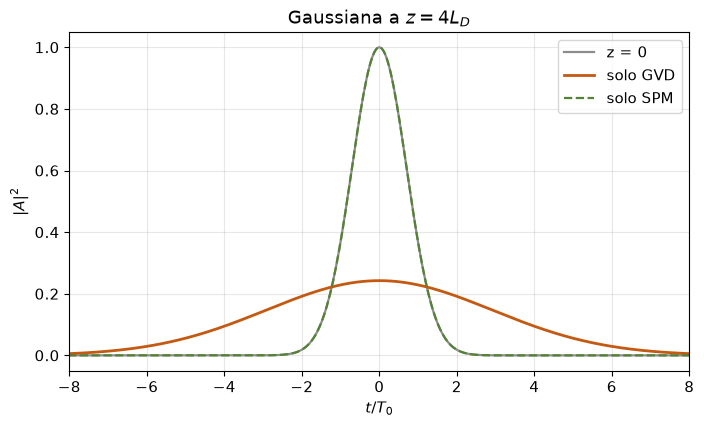

In [2]:
z = 4 * LD
steps = 1600
A0 = gaussian(P0)
A_gvd = split_step(A0, z, beta2, 0.0, steps)
A_spm = split_step(A0, z, 0.0, gamma, steps)

w0 = rms_width(A0)
exact = A0 * np.exp(1j * gamma * np.abs(A0)**2 * z)
print(f"rms iniziale     {w0:.3f}")
print(f"rms solo GVD     {rms_width(A_gvd):.3f}")
print(f"rms solo SPM     {rms_width(A_spm):.3f}")
print(f"errore SPM vs fase esatta  {np.max(np.abs(A_spm - exact)):.2e}")

fig, ax = plt.subplots()
ax.plot(t, np.abs(A0)**2, color="0.55", lw=1.6, label="z = 0")
ax.plot(t, np.abs(A_gvd)**2, color="#c45911", lw=2.0, label="solo GVD")
ax.plot(t, np.abs(A_spm)**2, color="#548235", lw=1.6, ls="--", label="solo SPM")
ax.set_xlim(-8, 8)
ax.set_xlabel(r"$t / T_0$")
ax.set_ylabel(r"$|A|^2$")
ax.set_title(r"Gaussiana a $z = 4 L_D$")
ax.legend()
plt.show()


## 2. Lo spettro fa il contrario

La GVD e una fase quadratica in frequenza: il modulo dello spettro non cambia.
La SPM e una fase nel tempo, $\phi(t)=\gamma |A|^2 z$, e il chirp $\delta\omega=-\partial_t\phi$ genera bande laterali.


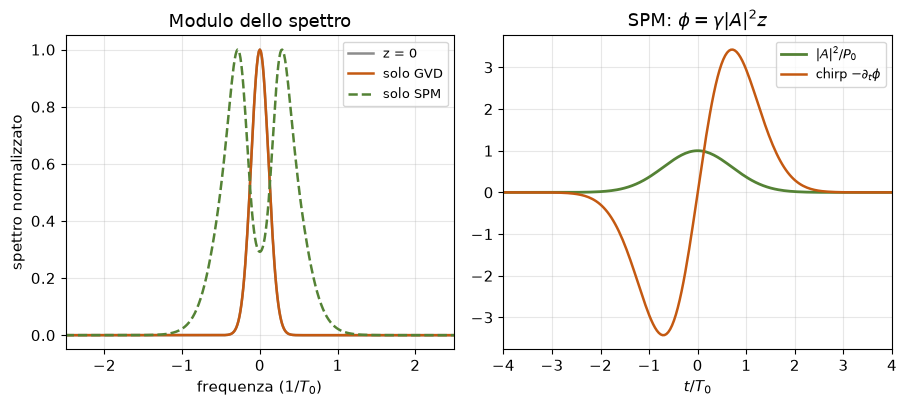

spettro GVD vs ingresso, max |S-S0| = 8.54e-13


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.2))

ax = axes[0]
for A, lab, col, ls in [
    (A0, "z = 0", "0.55", "-"),
    (A_gvd, "solo GVD", "#c45911", "-"),
    (A_spm, "solo SPM", "#548235", "--"),
]:
    f, S = spectrum(A)
    ax.plot(f, S, color=col, ls=ls, lw=1.8, label=lab)
ax.set_xlim(-2.5, 2.5)
ax.set_xlabel(r"frequenza ($1/T_0$)")
ax.set_ylabel("spettro normalizzato")
ax.set_title("Modulo dello spettro")
ax.legend(fontsize=9)

ax = axes[1]
phi = gamma * np.abs(A0)**2 * z
chirp = -np.gradient(phi, dt)
ax.plot(t, np.abs(A_spm)**2 / P0, color="#548235", lw=2.0, label=r"$|A|^2/P_0$")
ax.plot(t, chirp, color="#c45911", lw=1.8, label=r"chirp $-\partial_t\phi$")
ax.set_xlim(-4, 4)
ax.set_xlabel(r"$t / T_0$")
ax.set_title(r"SPM: $\phi=\gamma|A|^2 z$")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

f0, S0 = spectrum(A0)
fg, Sg = spectrum(A_gvd)
print(f"spettro GVD vs ingresso, max |S-S0| = {np.max(np.abs(Sg - S0)):.2e}")


## 3. Solitone: secante iperbolica

Con $\beta_2<0$ e $N=\sqrt{\gamma P_0 T_0^2/|\beta_2|}=1$ la soluzione che non cambia forma e

$$
A(z,t)=\sqrt{P_0}\,\mathrm{sech}(t/T_0)\,e^{i z/(2 L_D)}.
$$

La stessa secante con $\gamma=0$ si allarga. Una gaussiana con gli stessi $L_D$ e $L_{NL}$ non e un solitone.


rms sech iniziale          0.907
rms sech solo GVD          2.481
rms sech solitone          0.907
errore vs sech * exp(iz/2LD)  6.348e-04


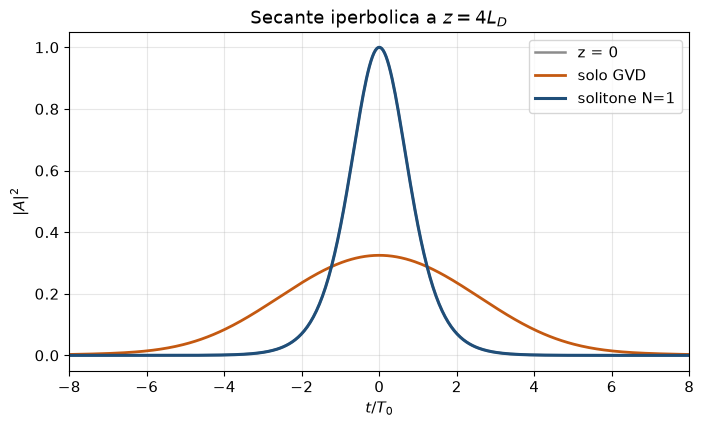

In [4]:
def sech_pulse(P):
    return np.sqrt(P) / np.cosh(t / T0)

As = sech_pulse(P0)
As_sol = split_step(As, z, beta2, gamma, steps)
As_gvd = split_step(As, z, beta2, 0.0, steps)
phase = np.exp(1j * z / (2 * LD))
err = np.max(np.abs(As_sol - As * phase))
print(f"rms sech iniziale          {rms_width(As):.3f}")
print(f"rms sech solo GVD          {rms_width(As_gvd):.3f}")
print(f"rms sech solitone          {rms_width(As_sol):.3f}")
print(f"errore vs sech * exp(iz/2LD)  {err:.3e}")

fig, ax = plt.subplots()
ax.plot(t, np.abs(As)**2, color="0.55", lw=1.8, label="z = 0")
ax.plot(t, np.abs(As_gvd)**2, color="#c45911", lw=2.0, label="solo GVD")
ax.plot(t, np.abs(As_sol)**2, color="#1f4e79", lw=2.2, label="solitone N=1")
ax.set_xlim(-8, 8)
ax.set_xlabel(r"$t / T_0$")
ax.set_ylabel(r"$|A|^2$")
ax.set_title(r"Secante iperbolica a $z = 4 L_D$")
ax.legend()
plt.show()


## 4. Cosa portarsi via

$L_D = T_0^2/|\beta_2|$ e la distanza su cui la GVD distorce l'impulso.
$L_{NL} = 1/(\gamma P_0)$ e la distanza su cui la SPM accumula un radiante di fase al picco.
$N = \sqrt{L_D/L_{NL}}$. Solo la secante con $N=1$ e GVD anomala resta ferma.
La gaussiana serve a separare i due effetti: il tempo lo muove $\beta_2$, la frequenza lo muove $\gamma$.
